# COU 07506 — Digital Signal Processing
## Week 01 — Lab 0: Setting Up the DSP Laboratory

**Name:** Hubert Steven Ngowi  
**Registration:** 24024246267  
**Stream:** 4  
**Course:** Bachelor in Engineering in Computer Engineering  
**Date:** 24 November 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

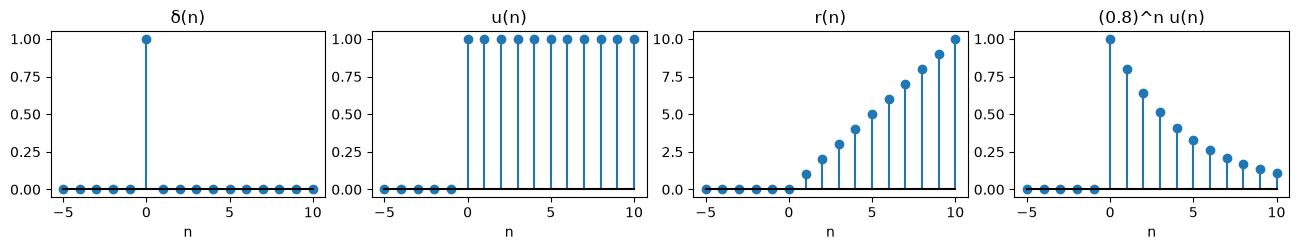

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)        # unit impulse
step  = (n >= 0).astype(float)        # unit step
ramp  = n * step                      # unit ramp
expo  = 0.8**n * step                 # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

I ran the code and got four stem plots. The delta plot has one stem at n = 0 and the rest are zero. The step is zero before n = 0 and becomes one from n = 0 onwards. The ramp follows n, so it keeps going up, and the (0.8)^n plot gets smaller and smaller after n = 0.

This is what I expected from the formulas in the handout, so I think the code is working. I used stem and not a continuous line because x(n) only exists at whole-number values of n.

## Task 1.2 — Change the parameters


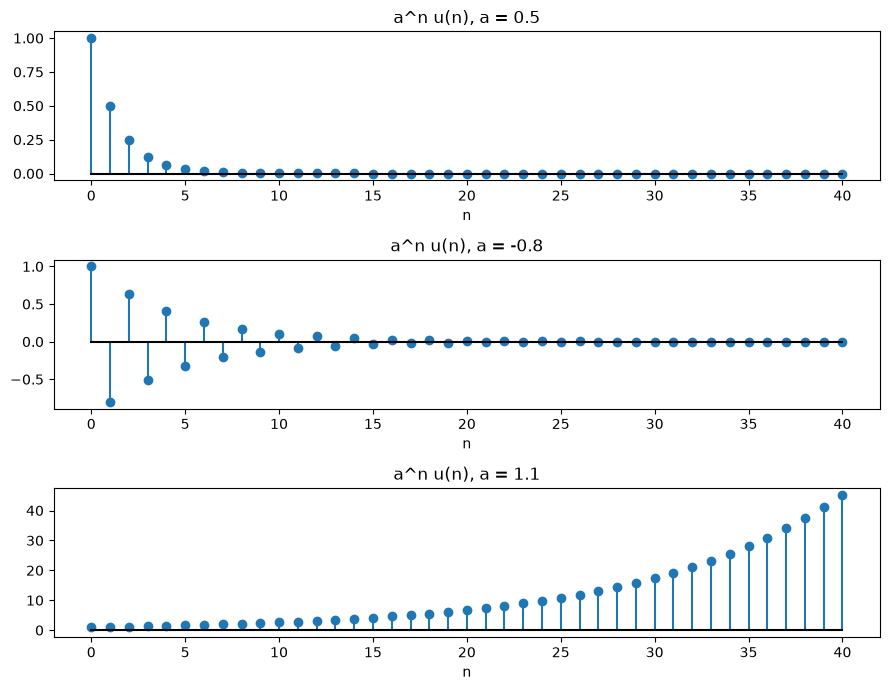

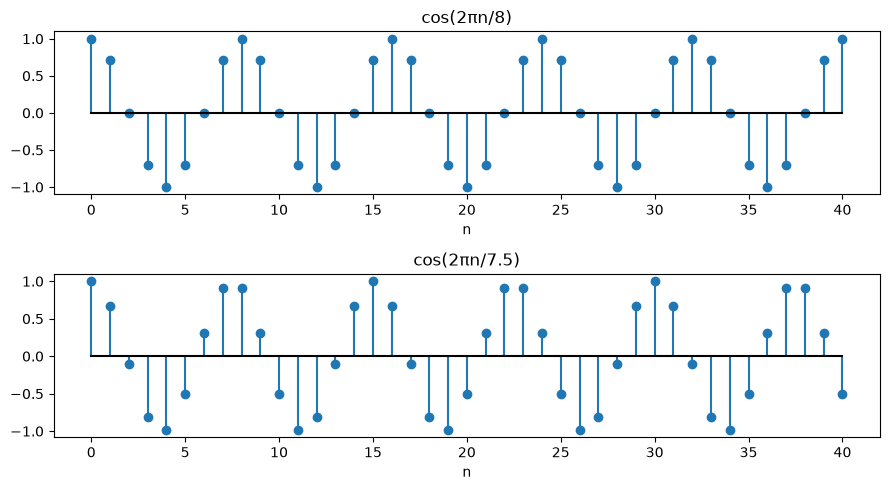

In [3]:
n = np.arange(0, 41)

fig, axes = plt.subplots(3, 1, figsize=(9, 7))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (a**n) * (n >= 0).astype(float)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a^n u(n), a = {a}")
    ax.set_xlabel("n")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(9, 5))
for ax, M in zip(axes, [8, 7.5]):
    ax.stem(n, np.cos(2*np.pi*n/M), basefmt="k-")
    ax.set_title(f"cos(2πn/{M})")
    ax.set_xlabel("n")
plt.tight_layout()
plt.show()

## Task 1.3 — Working with audio

fs = 44100 Hz, duration = 5.04 s, samples = 222186


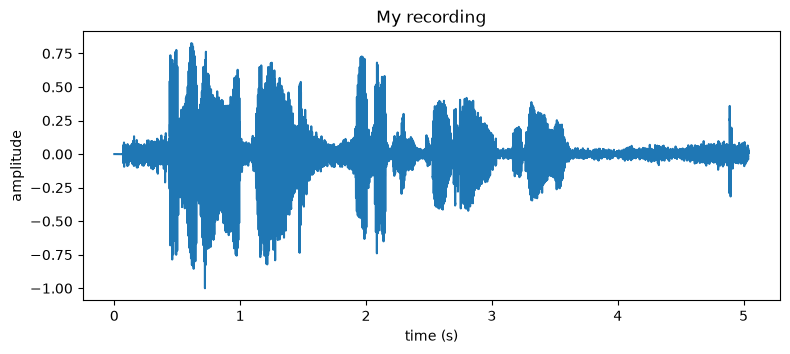

In [4]:
import os
from IPython.display import Audio

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

Audio(x, rate=fs)

## Analysis questions

1. My phone recorded at 44100 Hz, so it takes 44100 samples every second.
   For one minute in mono that is 44100 × 60 = 2,646,000 numbers. If each
   number is 16-bit (2 bytes), the file would be about 5.29 MB. I checked
   the multiplication with the code because it is easy to miss a zero.

2. I used a stem plot because x(n) only exists at integer n. If I used a
   continuous line it would look like the signal has values between the
   samples, which is not true.

3. When a = 1.1 the exponential keeps growing as n increases, so h(n)
   never settles down. That means the system is not BIBO stable: even a
   bounded input can give an output that keeps growing.

## Task 1.4 — The same in Octave (optional)
This task is optional
in the manual so i skipped it because, Tasks 1.1-1.3 were completed in Python/Jupyter.

## Task 1.5 — Repository and submission

Repository: https://github.com/hubertsteven61/COU07506-labs